# Diabetes Risk Prediction Using Machine Learning
**BITSF464 Machine Learning – Step 4: Python Implementation (initial)**

**Team:** Sherwin Gummadi

---
### What this notebook does
It implements the first working version of the pipeline proposed in our report (Figure 2) and is aligned with the project objectives and problem statements:

| Report item | Where it is addressed in this notebook |
|---|---|
| **Objective 1** – Ensemble models + Logistic Regression baseline with Stratified K-Fold CV | Sections 5–6 |
| **Objective 2** – Class-imbalance handling (SMOTE inside CV) and clinically relevant metrics (Recall, AUC-ROC) | Sections 3, 6, 7 |
| **Objective 3** – Interpretable predictions (SHAP on the best model) | Section 9 |
| **Problem Statement 1** – Ensemble + explainability | Sections 6, 9 |
| **Problem Statement 2** – Effect of SMOTE + stratified k-fold on performance / generalizability | Sections 6, 7, 8 |
| **Problem Statement 3** – Minimum deployable outputs (risk score + top features) | Sections 8, 9 |

**Dataset:** `synthetic_diabetes_dataset.xlsx` – 500 synthetic patients (not real patient data) with Age, Height, Weight, BMI, Blood Pressure, Insulin, Diabetes Pedigree Function and a binary `Outcome`.

## 1. Setup – install and import libraries
`imbalanced-learn` (SMOTE) and `shap` are not pre-installed in Colab, so we install them first. `scikit-learn`, `xgboost`, `pandas`, `matplotlib` and `seaborn` already come with Colab.

In [1]:
!pip install -q imbalanced-learn shap

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data collection – load the dataset
Upload `synthetic_diabetes_dataset.xlsx` when prompted (or place it in the Colab working directory / mount Google Drive and change `FILE_PATH`). The workbook has two sheets: **Patient Data** (the data) and **Notes** (column definitions).

In [2]:
FILE_PATH = "synthetic_diabetes_dataset.xlsx"

if not os.path.exists(FILE_PATH):
    from google.colab import files
    files.upload()          # choose synthetic_diabetes_dataset.xlsx

df = pd.read_excel(FILE_PATH, sheet_name="Patient Data")
print("Shape:", df.shape)
df.head()

Saving synthetic_diabetes_dataset.xlsx to synthetic_diabetes_dataset.xlsx
Shape: (500, 9)


,Patient_ID,Age,Height_cm,Weight_kg,BMI,Blood_Pressure,Insulin,Diabetes_Pedigree_Function,Outcome
0,1,53,178.3,90.0,28.31,67,147,0.310,0
1,2,32,174.1,72.8,24.02,60,102,0.273,0
2,3,59,159.5,67.5,26.53,89,267,0.528,1
3,4,62,152.5,75.4,32.42,81,41,0.473,1
4,5,21,145.0,58.3,27.73,63,63,0.175,0


## 3. Data cleaning and quality control
Before modelling we check for missing values, duplicate rows, implausible values and whether the derived `BMI` column is consistent with Height and Weight (the dataset notes say `BMI = Weight / (Height/100)²`).

In [3]:
print("Data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Patient_IDs:", df["Patient_ID"].duplicated().sum())

# Is BMI consistent with Height & Weight?
bmi_check = df["Weight_kg"] / (df["Height_cm"] / 100) ** 2
print("Max |BMI - recomputed BMI|:", round((bmi_check - df["BMI"]).abs().max(), 3))

# Summary statistics (look for implausible ranges)
df.describe().T.round(2)

Data types:
 Patient_ID                      int64
Age                             int64
Height_cm                     float64
Weight_kg                     float64
BMI                           float64
Blood_Pressure                  int64
Insulin                         int64
Diabetes_Pedigree_Function    float64
Outcome                         int64
dtype: object 

Missing values per column:
 Patient_ID                    0
Age                           0
Height_cm                     0
Weight_kg                     0
BMI                           0
Blood_Pressure                0
Insulin                       0
Diabetes_Pedigree_Function    0
Outcome                       0
dtype: int64 

Duplicate rows: 0
Duplicate Patient_IDs: 0
Max |BMI - recomputed BMI|: 0.005


,count,mean,std,min,25%,50%,75%,max
Patient_ID,500.0,250.50,144.48,1.00,125.75,250.50,375.25,500.00
Age,500.0,47.90,14.03,21.00,38.00,48.00,57.00,85.00
Height_cm,500.0,165.66,9.00,145.00,159.45,166.10,171.35,194.60
Weight_kg,500.0,78.47,17.41,35.70,65.97,77.75,89.70,146.30
BMI,500.0,28.53,5.53,16.98,24.86,28.58,32.26,44.01
Blood_Pressure,500.0,70.46,11.62,40.00,62.00,71.00,78.00,108.00
Insulin,500.0,92.76,54.50,15.00,55.00,82.00,116.25,398.00
Diabetes_Pedigree_Function,500.0,0.49,0.33,0.08,0.27,0.42,0.60,2.26
Outcome,500.0,0.37,0.48,0.00,0.00,0.00,1.00,1.00


## 4. Exploratory Data Analysis (EDA)
### 4.1 Class distribution – diabetic vs non-diabetic
Our report identifies **class imbalance** as an under-addressed gap (Gap 3), so the first thing to quantify is the diabetic / non-diabetic ratio.

                 count  percent
Outcome                        
No diabetes (0)    314     62.8
Diabetes (1)       186     37.2

Imbalance ratio (majority : minority) = 1.69 : 1


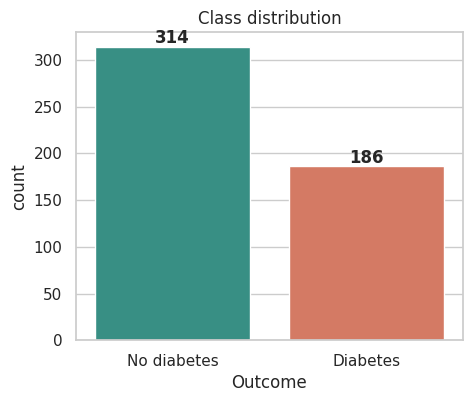

In [4]:
counts = df["Outcome"].value_counts().sort_index()
pct = df["Outcome"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(1)}).rename(index={0: "No diabetes (0)", 1: "Diabetes (1)"}))
print(f"\nImbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Outcome", data=df, palette=["#2a9d8f", "#e76f51"], ax=ax)
ax.set_xticklabels(["No diabetes", "Diabetes"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
ax.set_title("Class distribution")
plt.show()

### 4.2 Feature distributions by outcome
This shows which clinical variables separate diabetic from non-diabetic patients.

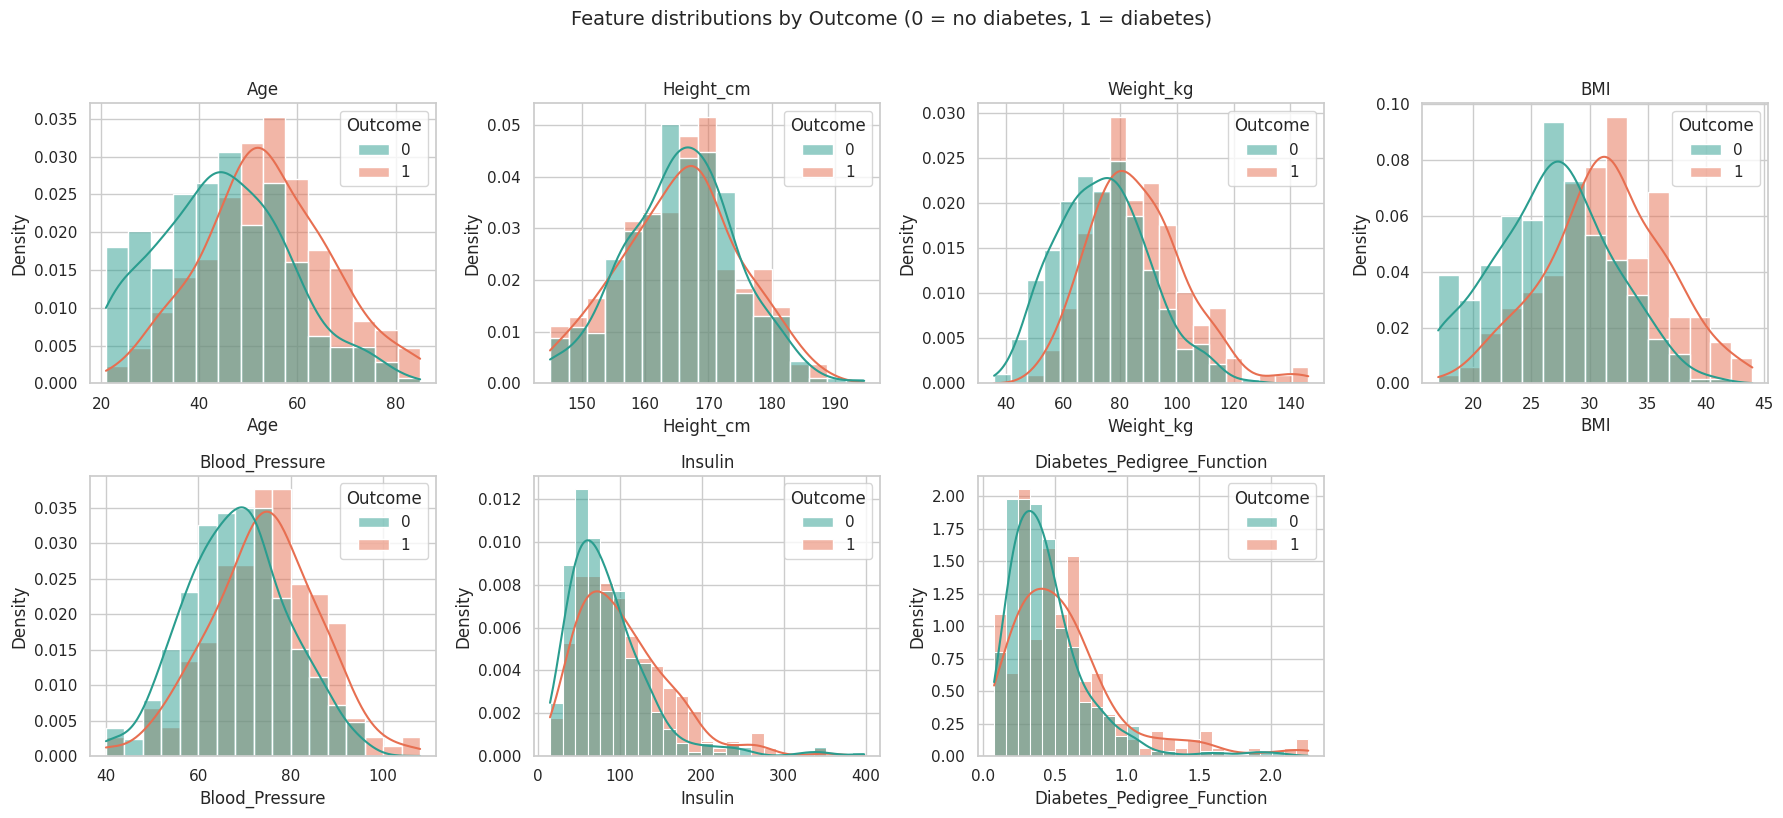

,Age,Height_cm,Weight_kg,BMI,Blood_Pressure,Insulin,Diabetes_Pedigree_Function
Outcome,,,,,,,
0,44.52,165.73,73.95,26.85,68.27,86.02,0.45
1,53.62,165.55,86.10,31.37,74.15,104.15,0.57


In [5]:
num_cols = ["Age", "Height_cm", "Weight_kg", "BMI", "Blood_Pressure", "Insulin", "Diabetes_Pedigree_Function"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, stat="density", common_norm=False,
                 palette=["#2a9d8f", "#e76f51"], ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
plt.suptitle("Feature distributions by Outcome (0 = no diabetes, 1 = diabetes)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# Group means
df.groupby("Outcome")[num_cols].mean().round(2)

### 4.3 Boxplots and outliers

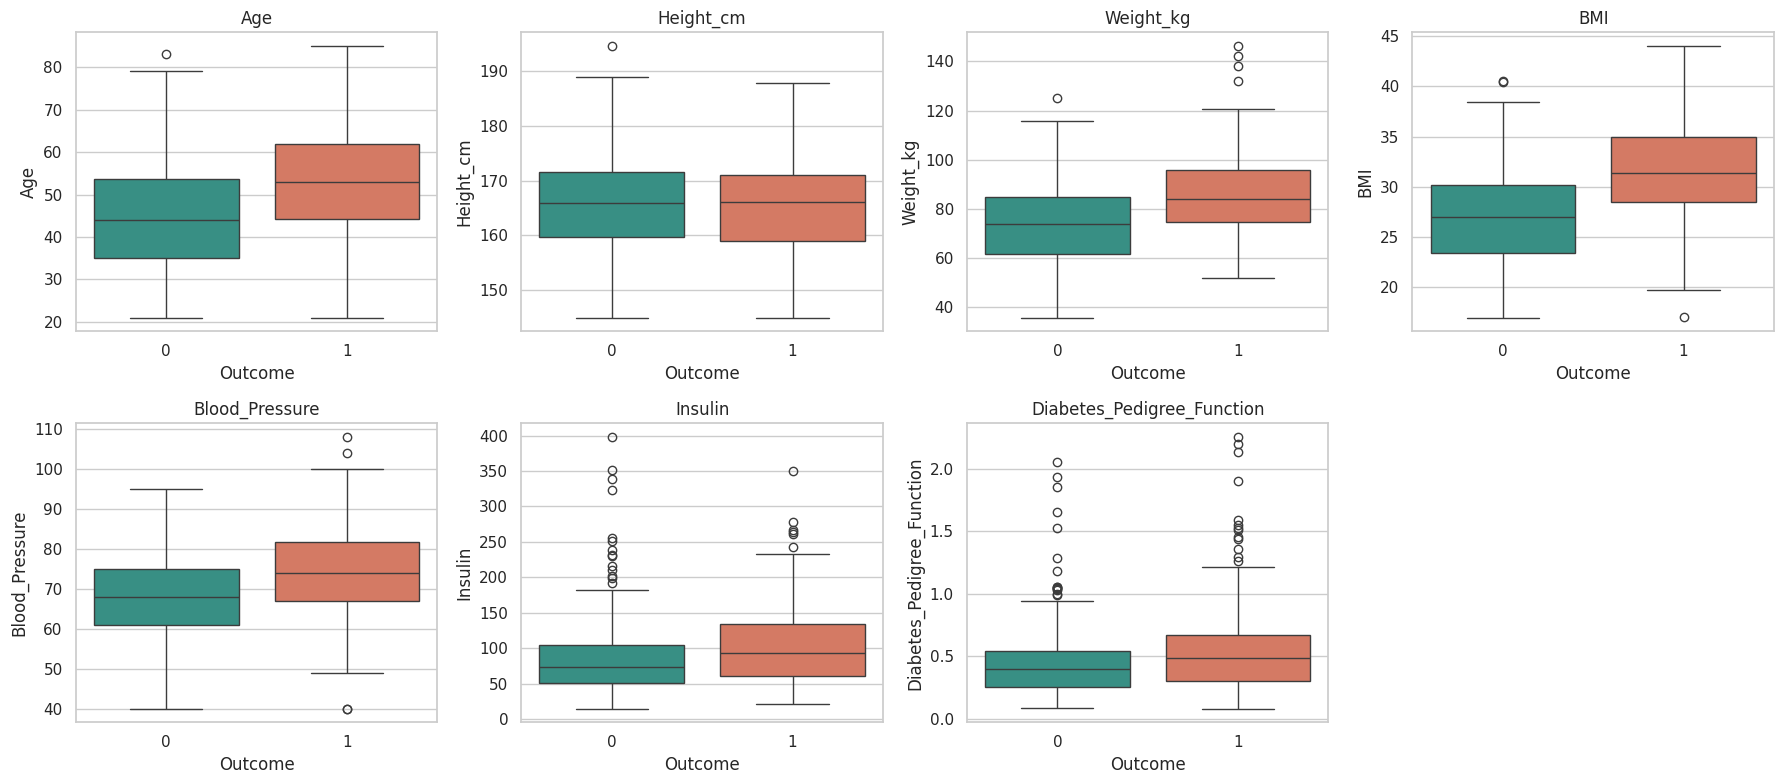

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Outcome", y=col, palette=["#2a9d8f", "#e76f51"], ax=ax)
    ax.set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 4.4 Correlation analysis
We look at (a) correlation between features (to detect redundancy, e.g. BMI vs Height/Weight) and (b) correlation of each feature with the `Outcome`.

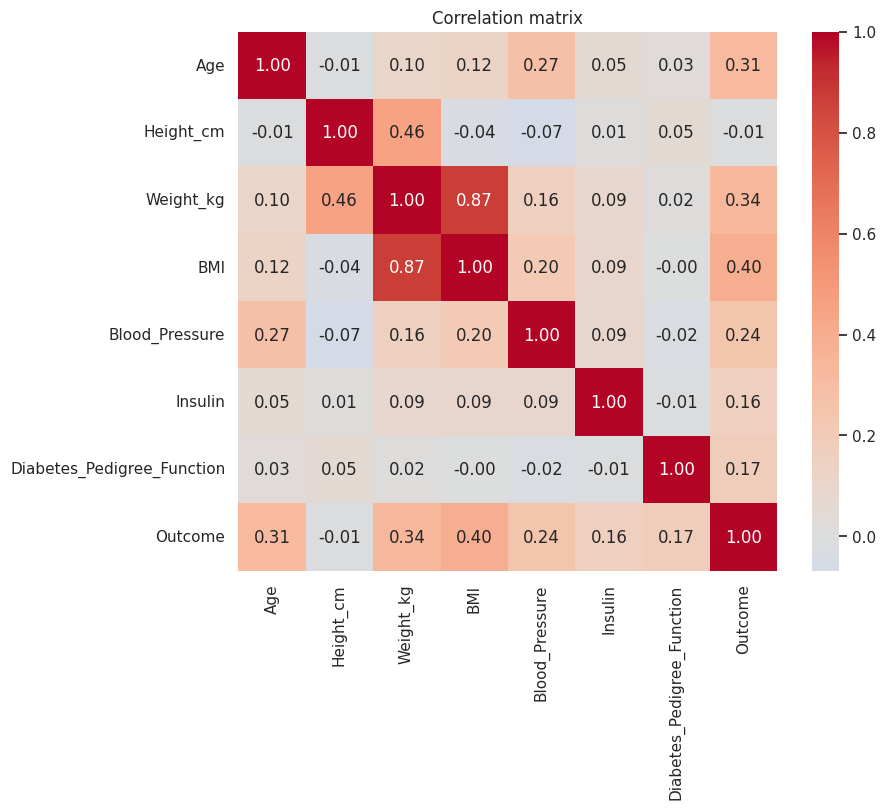

Correlation with Outcome:
BMI                           0.396
Weight_kg                     0.338
Age                           0.314
Blood_Pressure                0.245
Diabetes_Pedigree_Function    0.174
Insulin                       0.161
Height_cm                    -0.009
Name: Outcome, dtype: float64


In [7]:
corr = df.drop(columns="Patient_ID").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.show()

print("Correlation with Outcome:")
print(corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

## 5. Data preprocessing and feature engineering
**Decisions (with reasons):**
- **Drop `Patient_ID`** – an identifier carries no clinical meaning and could leak spurious patterns.
- **Drop `Height_cm` and `Weight_kg`** – `BMI` is computed from them, so keeping all three is redundant (multicollinearity hurts Logistic Regression and muddies SHAP attributions). BMI is the clinically standard variable.
- **Engineered features (clinically motivated, easy for a doctor to interpret):**
  - `Obese` = 1 if BMI ≥ 30
  - `High_BP` = 1 if diastolic BP ≥ 80 mm Hg
  - `Age_BMI` = Age × BMI / 100 (interaction: risk rises with both)
- **Scaling** is applied **inside the model pipeline** (only for Logistic Regression), so that it is learned on training folds only – this avoids data leakage. Tree-based models do not need scaling.
- **No missing values** were found, so no imputation is required.

Set `USE_ENGINEERED = False` to compare against the raw features only.

In [8]:
USE_ENGINEERED = True

data = df.copy()
data["Obese"]    = (data["BMI"] >= 30).astype(int)
data["High_BP"]  = (data["Blood_Pressure"] >= 80).astype(int)
data["Age_BMI"]  = data["Age"] * data["BMI"] / 100

base_features = ["Age", "BMI", "Blood_Pressure", "Insulin", "Diabetes_Pedigree_Function"]
eng_features  = ["Obese", "High_BP", "Age_BMI"]
features = base_features + (eng_features if USE_ENGINEERED else [])

X = data[features]
y = data["Outcome"]
print("Features used:", features)
print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

Features used: ['Age', 'BMI', 'Blood_Pressure', 'Insulin', 'Diabetes_Pedigree_Function', 'Obese', 'High_BP', 'Age_BMI']
X shape: (500, 8) | y shape: (500,)


,Age,BMI,Blood_Pressure,Insulin,Diabetes_Pedigree_Function,Obese,High_BP,Age_BMI
0,53,28.31,67,147,0.310,0,0,15.0043
1,32,24.02,60,102,0.273,0,0,7.6864
2,59,26.53,89,267,0.528,0,1,15.6527
3,62,32.42,81,41,0.473,1,1,20.1004
4,21,27.73,63,63,0.175,0,0,5.8233


## 6. Basic model development with Stratified K-Fold CV (± SMOTE)
**Models (Objective 1):** Logistic Regression (interpretable baseline), Random Forest, Gradient Boosting, XGBoost.

**Validation (Objective 2 / Problem Statement 2):** 5-fold **Stratified** K-Fold, so every fold keeps the same diabetic / non-diabetic ratio. Every model is evaluated **twice – without and with SMOTE**.

**Important:** SMOTE is placed *inside* an `imblearn` Pipeline, so it is applied **only to the training folds** and the validation fold stays untouched (real patients only). Applying SMOTE before splitting would leak synthetic neighbours of test patients into training and inflate the scores.

**Metrics:** Accuracy, Precision, **Recall** (missing a diabetic patient is the costly error), F1 and **ROC-AUC** – not accuracy alone.

In [9]:
def build_pipeline(model_name, use_smote):
    # Models are built fresh each time so folds never share fitted state.
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                 eval_metric="logloss", random_state=RANDOM_STATE),
    }
    steps = []
    if model_name == "Logistic Regression":
        steps.append(("scaler", StandardScaler()))
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", models[model_name]))
    return ImbPipeline(steps)

MODEL_NAMES = ["Logistic Regression", "Random Forest", "Gradient Boosting", "XGBoost"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for name in MODEL_NAMES:
    for use_smote in [False, True]:
        pipe = build_pipeline(name, use_smote)
        cv = cross_validate(pipe, X, y, cv=skf, scoring=scoring)
        row = {"Model": name, "SMOTE": "With" if use_smote else "Without"}
        for m in scoring:
            row[f"{m}_mean"] = cv[f"test_{m}"].mean()
            row[f"{m}_std"]  = cv[f"test_{m}"].std()
        rows.append(row)
        print(f"done: {name:20s} | SMOTE = {use_smote}")

results = pd.DataFrame(rows)
results.round(3)

done: Logistic Regression  | SMOTE = False
done: Logistic Regression  | SMOTE = True
done: Random Forest        | SMOTE = False
done: Random Forest        | SMOTE = True
done: Gradient Boosting    | SMOTE = False
done: Gradient Boosting    | SMOTE = True
done: XGBoost              | SMOTE = False
done: XGBoost              | SMOTE = True


,Model,SMOTE,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,Without,0.748,0.033,0.709,0.079,0.570,0.034,0.628,0.029,0.802,0.035
1,Logistic Regression,With,0.722,0.044,0.609,0.045,0.705,0.076,0.653,0.056,0.801,0.037
2,Random Forest,Without,0.720,0.041,0.656,0.081,0.532,0.072,0.585,0.066,0.771,0.051
3,Random Forest,With,0.700,0.032,0.593,0.038,0.613,0.082,0.601,0.057,0.766,0.044
4,Gradient Boosting,Without,0.728,0.032,0.666,0.067,0.553,0.043,0.603,0.040,0.782,0.027
5,Gradient Boosting,With,0.712,0.022,0.606,0.030,0.645,0.065,0.624,0.039,0.772,0.021
6,XGBoost,Without,0.722,0.033,0.649,0.054,0.553,0.067,0.596,0.055,0.784,0.037
7,XGBoost,With,0.704,0.021,0.595,0.027,0.650,0.043,0.620,0.024,0.779,0.026


## 7. Initial model evaluation – comparing models and the effect of SMOTE
The table below shows mean ± standard deviation across the 5 folds. The std matters: with only 500 patients, small differences between models may be within fold-to-fold noise.

,Model,SMOTE,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Without,0.748 ± 0.033,0.709 ± 0.079,0.570 ± 0.034,0.628 ± 0.029,0.802 ± 0.035
1,Logistic Regression,With,0.722 ± 0.044,0.609 ± 0.045,0.705 ± 0.076,0.653 ± 0.056,0.801 ± 0.037
2,Random Forest,Without,0.720 ± 0.041,0.656 ± 0.081,0.532 ± 0.072,0.585 ± 0.066,0.771 ± 0.051
3,Random Forest,With,0.700 ± 0.032,0.593 ± 0.038,0.613 ± 0.082,0.601 ± 0.057,0.766 ± 0.044
4,Gradient Boosting,Without,0.728 ± 0.032,0.666 ± 0.067,0.553 ± 0.043,0.603 ± 0.040,0.782 ± 0.027
5,Gradient Boosting,With,0.712 ± 0.022,0.606 ± 0.030,0.645 ± 0.065,0.624 ± 0.039,0.772 ± 0.021
6,XGBoost,Without,0.722 ± 0.033,0.649 ± 0.054,0.553 ± 0.067,0.596 ± 0.055,0.784 ± 0.037
7,XGBoost,With,0.704 ± 0.021,0.595 ± 0.027,0.650 ± 0.043,0.620 ± 0.024,0.779 ± 0.026


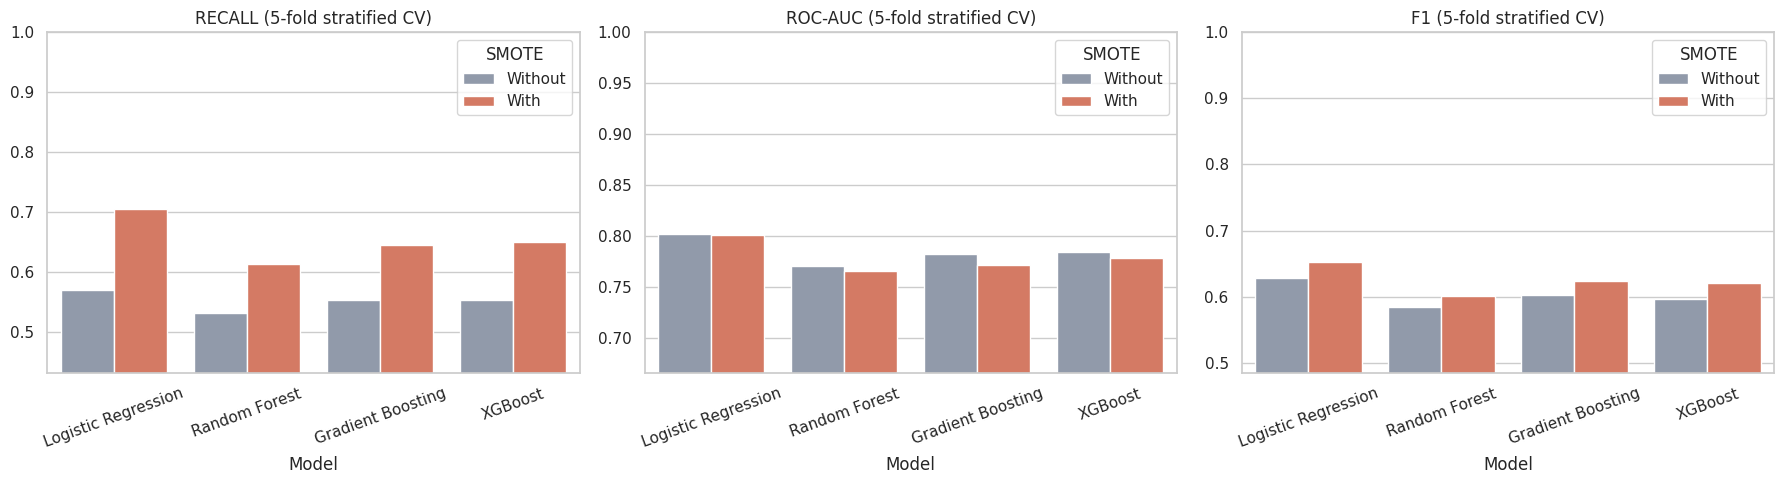


Effect of SMOTE (With − Without):


,Δ Recall,Δ ROC-AUC,Δ F1
Model,,,
Gradient Boosting,0.091,-0.010,0.021
Logistic Regression,0.135,-0.001,0.024
Random Forest,0.081,-0.005,0.016
XGBoost,0.097,-0.006,0.025


In [10]:
display_df = results[["Model", "SMOTE"]].copy()
for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    display_df[m] = results.apply(lambda r: f"{r[m + '_mean']:.3f} ± {r[m + '_std']:.3f}", axis=1)
display(display_df)

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["recall", "roc_auc", "f1"]):
    sns.barplot(data=results, x="Model", y=f"{metric}_mean", hue="SMOTE",
                palette=["#8d99ae", "#e76f51"], ax=ax)
    ax.set_title(metric.upper().replace("_", "-") + " (5-fold stratified CV)")
    ax.set_ylabel("")
    ax.set_ylim(max(0, results[f"{metric}_mean"].min() - 0.1), 1.0)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Effect of SMOTE: with minus without
piv = results.pivot(index="Model", columns="SMOTE", values=["recall_mean", "roc_auc_mean", "f1_mean"])
effect = pd.DataFrame({
    "Δ Recall":  piv["recall_mean"]["With"]  - piv["recall_mean"]["Without"],
    "Δ ROC-AUC": piv["roc_auc_mean"]["With"] - piv["roc_auc_mean"]["Without"],
    "Δ F1":      piv["f1_mean"]["With"]      - piv["f1_mean"]["Without"],
}).round(3)
print("\nEffect of SMOTE (With − Without):")
effect

### 7.1 Select the best configuration
We rank by **ROC-AUC** (threshold-independent), using **Recall** as the tie-breaker, because the clinical priority is to catch at-risk patients. This best configuration is carried forward to the hold-out evaluation and SHAP.

> **Note for the report:** the dataset is only ~37% diabetic (mild imbalance), so SMOTE may help Recall slightly but may not change ROC-AUC much. Whatever the result is, report it honestly – a "SMOTE helps little here" finding is still a valid answer to Problem Statement 2.

In [11]:
ranked = results.sort_values(["roc_auc_mean", "recall_mean"], ascending=False).reset_index(drop=True)
display(ranked[["Model", "SMOTE", "roc_auc_mean", "recall_mean", "f1_mean"]].round(3))

best_name  = ranked.loc[0, "Model"]
best_smote = ranked.loc[0, "SMOTE"] == "With"
print(f"\nBest configuration -> Model: {best_name} | SMOTE: {best_smote}")

,Model,SMOTE,roc_auc_mean,recall_mean,f1_mean
0,Logistic Regression,Without,0.802,0.570,0.628
1,Logistic Regression,With,0.801,0.705,0.653
2,XGBoost,Without,0.784,0.553,0.596
3,Gradient Boosting,Without,0.782,0.553,0.603
4,XGBoost,With,0.779,0.650,0.620
5,Gradient Boosting,With,0.772,0.645,0.624
6,Random Forest,Without,0.771,0.532,0.585
7,Random Forest,With,0.766,0.613,0.601



Best configuration -> Model: Logistic Regression | SMOTE: False


## 8. Hold-out evaluation of the best model
Cross-validation gave us the model choice; now we fit the chosen configuration once on 80% of the data and test it on a **20% stratified hold-out set** that no step has seen. We inspect the confusion matrix, ROC curve, and the **top predictive features** (permutation importance – a quick model-agnostic check before SHAP).

We also output a simple **risk score** (predicted probability of diabetes) for a few patients, which is the prototype output described in Problem Statement 3.

Hold-out results for Logistic Regression (SMOTE = False)
Accuracy : 0.800
Precision: 0.774
Recall   : 0.649
F1       : 0.706
ROC-AUC  : 0.833

              precision    recall  f1-score   support

 No diabetes       0.81      0.89      0.85        63
    Diabetes       0.77      0.65      0.71        37

    accuracy                           0.80       100
   macro avg       0.79      0.77      0.78       100
weighted avg       0.80      0.80      0.80       100



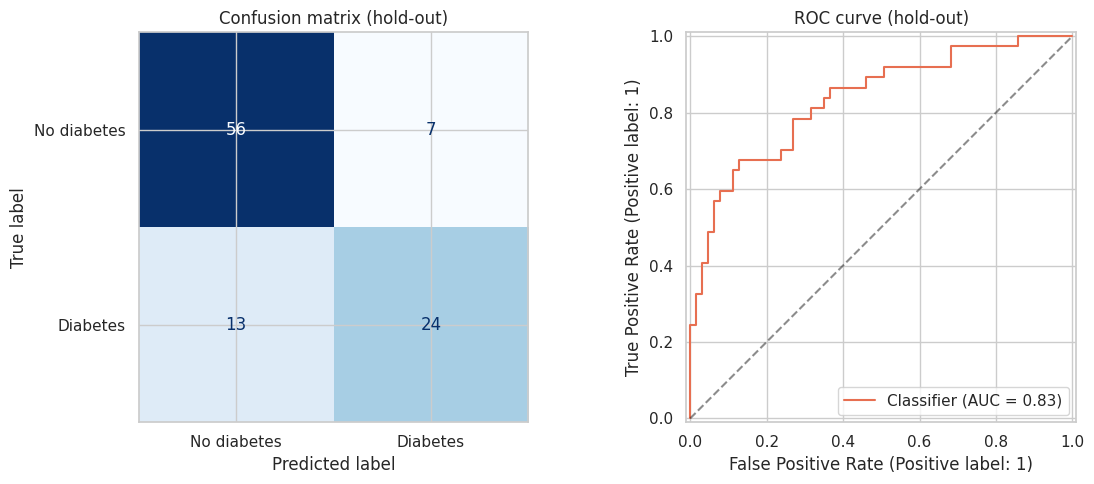

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

best_pipe = build_pipeline(best_name, best_smote)
best_pipe.fit(X_train, y_train)

y_pred  = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

print(f"Hold-out results for {best_name} (SMOTE = {best_smote})")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1       : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No diabetes", "Diabetes"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (hold-out)")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], color="#e76f51")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("ROC curve (hold-out)")
plt.tight_layout()
plt.show()

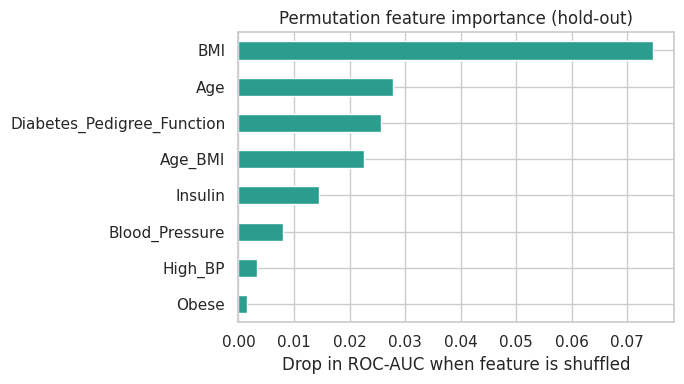

,Age,BMI,Blood_Pressure,Insulin,Diabetes_Pedigree_Function,Obese,High_BP,Age_BMI,Risk_Score_%,Actual_Outcome
154,47,32.31,71,55,0.465,1,0,15.1857,44.3,0
479,85,39.00,91,105,0.344,1,1,33.1500,97.2,1
310,66,22.55,53,52,0.668,0,0,14.8830,22.8,0
488,35,29.92,61,79,0.929,0,0,10.4720,32.4,0
487,54,21.11,62,98,0.676,0,0,11.3994,15.7,1


In [13]:
# Permutation importance on the hold-out set (quick feature-importance check)
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
imp.plot(kind="barh", color="#2a9d8f")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.title("Permutation feature importance (hold-out)")
plt.tight_layout()
plt.show()

# Prototype output: risk score for 5 hold-out patients
demo = X_test.head(5).copy()
demo["Risk_Score_%"] = (best_pipe.predict_proba(demo)[:, 1] * 100).round(1)
demo["Actual_Outcome"] = y_test.loc[demo.index].values
demo

### 8.1 Generalizability check across patient subgroups
Our report (Gap 2) criticises papers for reporting a single overall score. As a first step towards subgroup evaluation, we generate **out-of-fold predictions** (each patient is predicted by a model that never saw them) and compare Recall and ROC-AUC across **age groups** and **BMI categories**. Large gaps between groups would suggest the model does not generalise equally well to all patients.

In [14]:
oof_proba = cross_val_predict(build_pipeline(best_name, best_smote), X, y, cv=skf, method="predict_proba")[:, 1]
oof_pred  = (oof_proba >= 0.5).astype(int)

eval_df = data[["Age", "BMI"]].copy()
eval_df["y"] = y.values
eval_df["pred"] = oof_pred
eval_df["proba"] = oof_proba
eval_df["Age_Group"] = pd.cut(eval_df["Age"], bins=[0, 39, 59, 120], labels=["<40", "40–59", "60+"])
eval_df["BMI_Group"] = pd.cut(eval_df["BMI"], bins=[0, 24.99, 29.99, 100],
                              labels=["Normal (<25)", "Overweight (25–30)", "Obese (30+)"])

def subgroup_report(group_col):
    out = []
    for g, d in eval_df.groupby(group_col):
        auc = roc_auc_score(d["y"], d["proba"]) if d["y"].nunique() == 2 else np.nan
        out.append({"Group": g, "n": len(d), "Diabetic %": round(d["y"].mean() * 100, 1),
                    "Recall": round(recall_score(d["y"], d["pred"], zero_division=0), 3),
                    "Precision": round(precision_score(d["y"], d["pred"], zero_division=0), 3),
                    "ROC-AUC": round(auc, 3)})
    return pd.DataFrame(out)

print("By age group:");  display(subgroup_report("Age_Group"))
print("By BMI group:");  display(subgroup_report("BMI_Group"))

By age group:


,Group,n,Diabetic %,Recall,Precision,ROC-AUC
0,<40,139,18.7,0.346,0.600,0.822
1,40–59,260,38.1,0.455,0.652,0.716
2,60+,101,60.4,0.852,0.765,0.804


By BMI group:


,Group,n,Diabetic %,Recall,Precision,ROC-AUC
0,Normal (<25),129,16.3,0.143,0.750,0.798
1,Overweight (25–30),174,28.7,0.300,0.556,0.706
2,Obese (30+),197,58.4,0.765,0.727,0.755


## 9. Explainability with SHAP (Objective 3 / Problem Statement 1)
SHAP shows **how much each feature pushed a prediction towards or away from "diabetes"**:
- the **summary (beeswarm) plot** gives the *global* picture – which features matter most overall and in which direction;
- the **waterfall plot** gives the *per-patient* explanation – the "top explanatory features" that make up our prototype output.

The code handles both tree models and Logistic Regression, depending on which model won in Section 7.1.

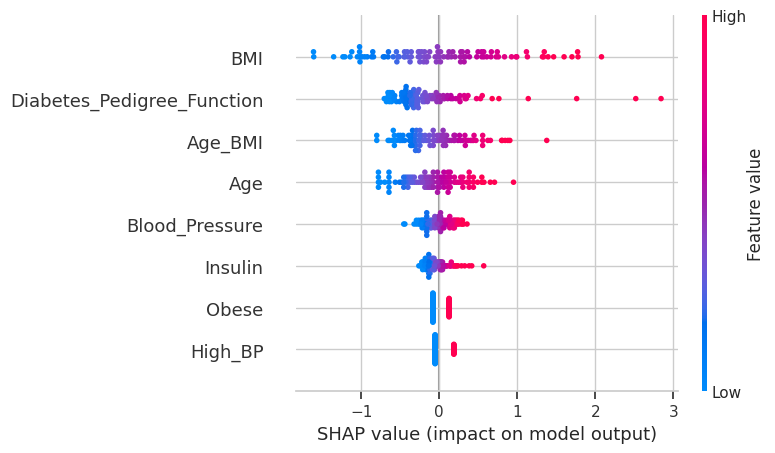

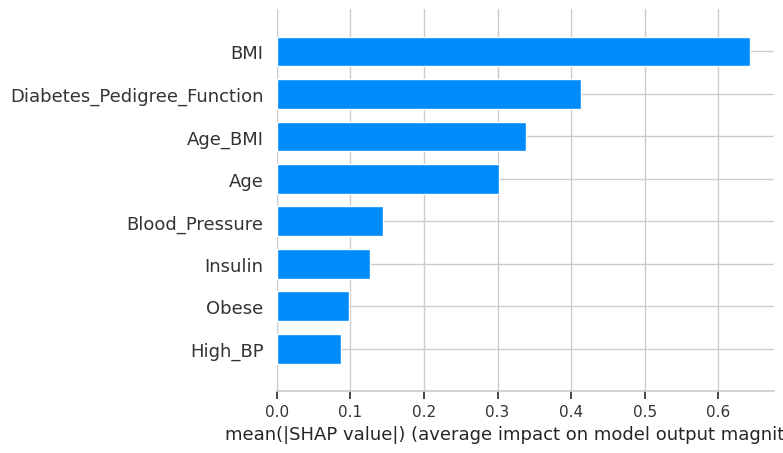

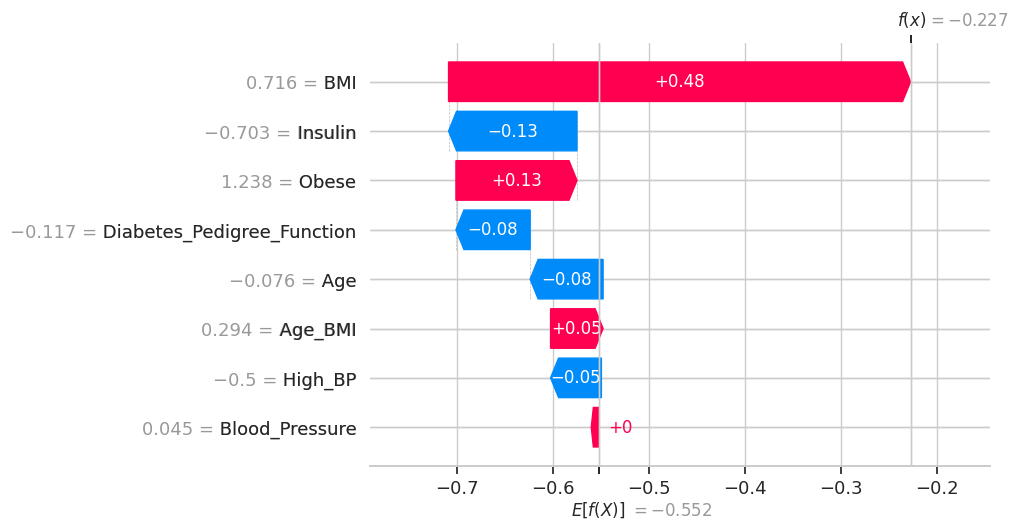

In [15]:
import shap

clf = best_pipe.named_steps["clf"]

if best_name == "Logistic Regression":
    scaler = best_pipe.named_steps["scaler"]
    X_train_t = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
    X_test_t  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)
    explainer = shap.Explainer(clf, X_train_t)
    sv = explainer(X_test_t)
else:
    explainer = shap.TreeExplainer(clf)
    sv = explainer(X_test)
    # Some versions return one set of values per class -> keep the 'diabetes' class
    if sv.values.ndim == 3:
        sv = sv[:, :, 1]

# Global explanation
shap.summary_plot(sv.values, X_test, show=True)
shap.summary_plot(sv.values, X_test, plot_type="bar", show=True)

# Per-patient explanation (first hold-out patient)
shap.plots.waterfall(sv[0])

## 10. Summary of this implementation stage and next steps

**Completed so far**
- Loaded and quality-checked the dataset (no missing values / duplicates; BMI consistent with Height & Weight).
- EDA: class balance, feature distributions, outliers, correlations.
- Preprocessing & feature engineering (dropped ID and redundant Height/Weight; added `Obese`, `High_BP`, `Age_BMI`).
- Trained Logistic Regression, Random Forest, Gradient Boosting and XGBoost with **5-fold Stratified CV**, each **with and without SMOTE** (SMOTE applied on training folds only).
- Evaluated with Recall, Precision, F1, ROC-AUC (not accuracy alone), plus a hold-out test and a subgroup check.
- Added SHAP global and per-patient explanations for the best model.

**Planned next steps**
1. Hyperparameter tuning (`GridSearchCV` / `RandomizedSearchCV`) inside the stratified CV loop.
2. Repeated stratified CV (e.g. `RepeatedStratifiedKFold`) and confidence intervals for a more stable comparison on 500 patients.
3. Decision-threshold tuning to reach a target recall (e.g. ≥ 0.85) and report the precision trade-off.
4. Compare against a single decision tree baseline (promised in the report's Contributions section).
5. External validation on a real dataset (e.g. Pima Indians Diabetes) since the current data are **synthetic**, and discuss deployment considerations (workflow integration, monitoring, governance).

> ⚠️ **Limitation to state in the report:** the dataset is synthetic (randomly generated with risk rising with age, BMI, blood pressure and pedigree score), so performance here shows the pipeline works but does not prove clinical validity.